# Análisis Exploratorio y Preprocesamiento de datos

## Carga de datos

In [1]:
from pathlib import Path
import pandas as pd
import random
from PIL import Image, ImageOps

import shutil

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
RAW_DIR = Path("data/raw/Digital images of defective and good condition tyres")

assert RAW_DIR.exists(), f"No se encontró la carpeta: {RAW_DIR.resolve()}"

In [3]:
CLASES = ["defective", "good"]
IMG_SIZE = (224, 224)
RAW_DIR = Path("data/raw/Digital images of defective and good condition tyres")
PROCESSED_DIR = Path("data/processed")

In [4]:
registros = []
for clase in CLASES:
    carpeta_clase = RAW_DIR / clase
    assert carpeta_clase.exists(), f"No se encontró la carpeta: {carpeta_clase}"
    
    for ruta in carpeta_clase.glob("*"):
        if ruta.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
            registros.append({"filepath": str(ruta), "label": clase})

df = pd.DataFrame(registros)
print("Conteo por clase:\n", df["label"].value_counts())

Conteo por clase:
 label
defective    1028
good          828
Name: count, dtype: int64


In [5]:
df = pd.DataFrame(registros)
print("Conteo por clase:\n", df["label"].value_counts())

Conteo por clase:
 label
defective    1028
good          828
Name: count, dtype: int64


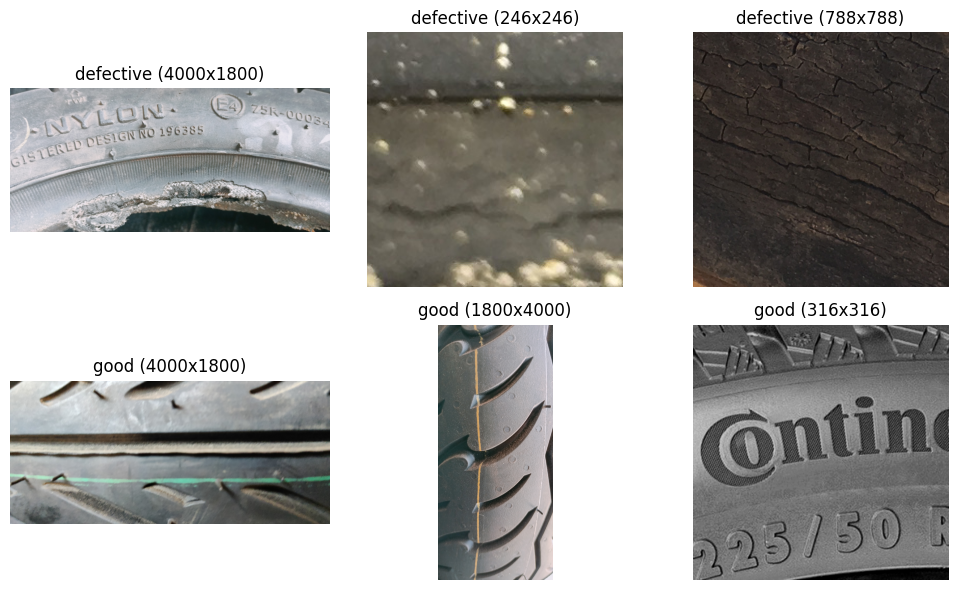

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for fila, clase in enumerate(CLASES):
    muestras = df[df["label"] == clase].sample(3, random_state=42)
    for col, (_, row) in enumerate(muestras.iterrows()):
        img = Image.open(row["filepath"])
        axes[fila, col].imshow(img)
        axes[fila, col].set_title(f"{clase} ({img.size[0]}x{img.size[1]})")
        axes[fila, col].axis("off")
plt.tight_layout()
plt.show()

## División estratificada


In [7]:
#70 % Train, 15 % Test, 15 % Val
train_df, test_full_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)
val_df, test_df = train_test_split(
    test_full_df, test_size=0.50, stratify=test_full_df["label"], random_state=42
)

splits = {"train": train_df, "val": val_df, "test": test_df}

In [8]:
for key in splits.keys():
    print(f"shape {key}: {splits[key].shape}")

shape train: (1299, 2)
shape val: (278, 2)
shape test: (279, 2)


## Redimensionar las imágenes

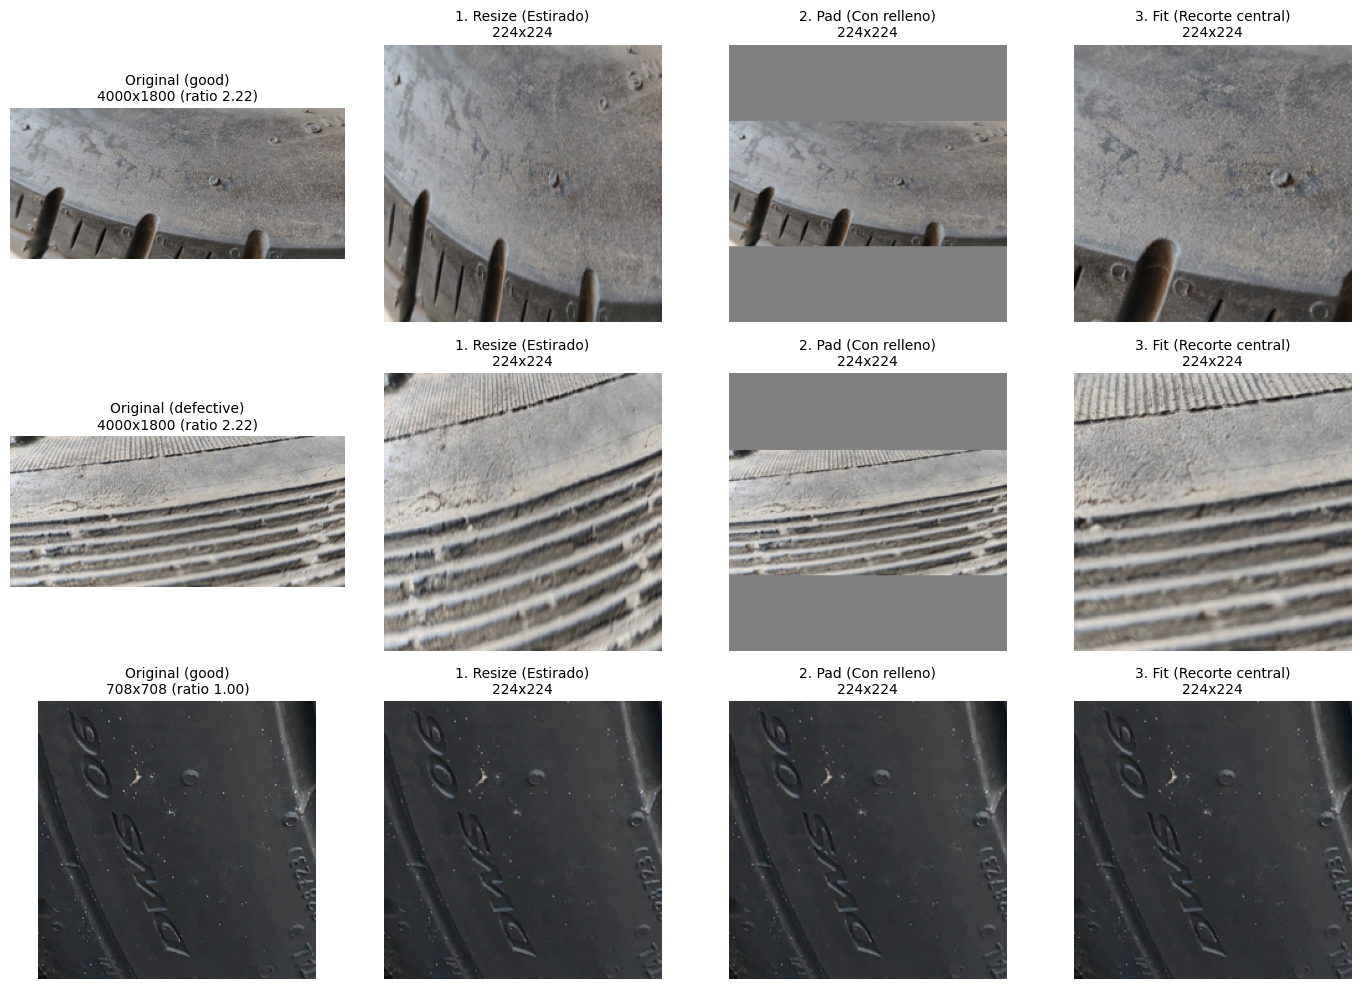

In [9]:
# Reunir todas las rutas válidas y elegir 3 al azar
todas_las_imagenes = [
    ruta for ruta in RAW_DIR.rglob("*")
    if ruta.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

ejemplos = random.sample(todas_las_imagenes, 3)

# Graficar Original vs. las 3 estrategias de reescalado
fig, axes = plt.subplots(len(ejemplos), 4, figsize=(14, 10))

for fila, ruta in enumerate(ejemplos):
    with Image.open(ruta) as img:
        img_rgb = img.convert("RGB")
        w, h = img_rgb.size
        ratio = max(w / h, h / w)
        
        # Mostrar las 3 transformaciones
        img_stretch = img_rgb.resize(IMG_SIZE, Image.Resampling.BICUBIC)
        img_pad = ImageOps.pad(img_rgb, IMG_SIZE, method=Image.Resampling.BICUBIC, color=(128, 128, 128))
        img_fit = ImageOps.fit(img_rgb, IMG_SIZE, method=Image.Resampling.BICUBIC)
        
        versiones = [
            (img_rgb, f"Original ({ruta.parent.name})\n{w}x{h} (ratio {ratio:.2f})"),
            (img_stretch, "1. Resize (Estirado)\n224x224"),
            (img_pad, "2. Pad (Con relleno)\n224x224"),
            (img_fit, "3. Fit (Recorte central)\n224x224")
        ]
        
        for col, (imagen, titulo) in enumerate(versiones):
            axes[fila, col].imshow(imagen)
            axes[fila, col].set_title(titulo, fontsize=10)
            axes[fila, col].axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Redimensionar a partir de resize()
if PROCESSED_DIR.exists():
    shutil.rmtree(PROCESSED_DIR)  # Limpia ejecuciones anteriores

for split_name, split_df in splits.items():
    for idx, row in split_df.iterrows():
        destino_dir = PROCESSED_DIR / split_name / row["label"]
        destino_dir.mkdir(parents=True, exist_ok=True)
        
        with Image.open(row["filepath"]) as img:
            # Convertir a RGB (evita errores si alguna imagen viene en RGBA o escala de grises)
            img_rgb = img.convert("RGB").resize(IMG_SIZE) # Uso de resize()
            nombre_salida = f"{Path(row['filepath']).stem}.jpg"
            img_rgb.save(destino_dir / nombre_salida, quality=95)

In [11]:
for split_name in splits:
    for clase in CLASES:
        n = len(list((PROCESSED_DIR / split_name / clase).glob("*.jpg")))
        print(f"  {split_name}/{clase}: {n} imágenes")

  train/defective: 719 imágenes
  train/good: 580 imágenes
  val/defective: 154 imágenes
  val/good: 124 imágenes
  test/defective: 155 imágenes
  test/good: 124 imágenes


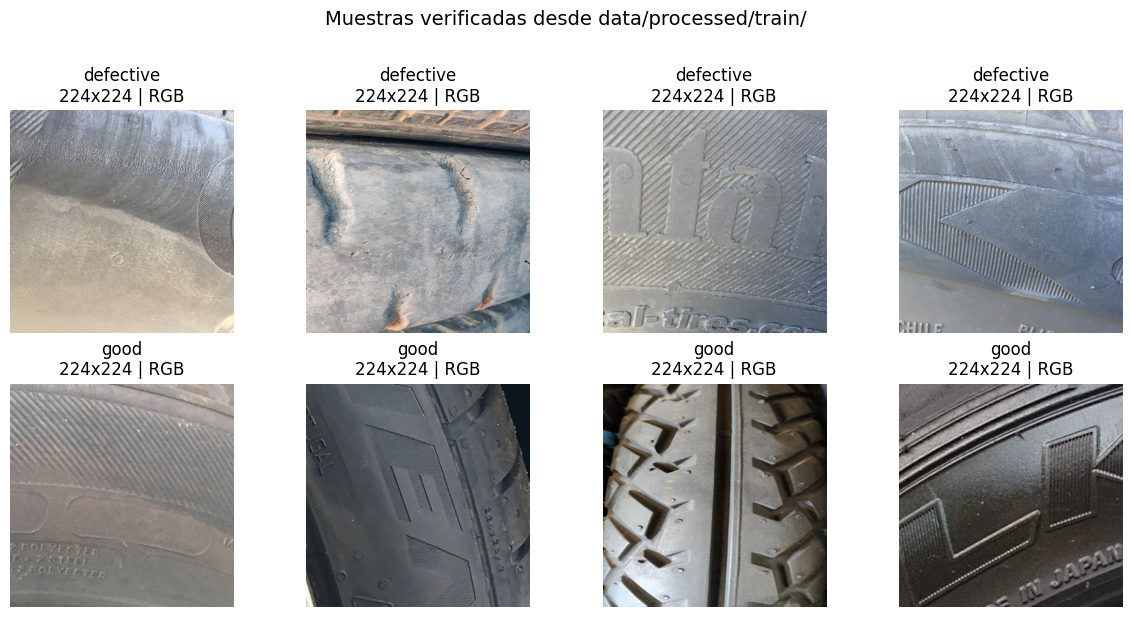

In [12]:
PROCESSED_TRAIN_DIR = Path("data/processed/train")
CLASES = ["defective", "good"]
MUESTRAS_POR_CLASE = 4

fig, axes = plt.subplots(len(CLASES), MUESTRAS_POR_CLASE, figsize=(12, 6))

for fila, clase in enumerate(CLASES):
    carpeta = PROCESSED_TRAIN_DIR / clase
    imagenes = list(carpeta.glob("*.jpg"))
    
    # Elegir muestras aleatorias
    seleccion = random.sample(imagenes, min(MUESTRAS_POR_CLASE, len(imagenes)))
    
    for col, ruta_img in enumerate(seleccion):
        with Image.open(ruta_img) as img:
            axes[fila, col].imshow(img)
            axes[fila, col].set_title(f"{clase}\n{img.size[0]}x{img.size[1]} | {img.mode}")
            axes[fila, col].axis("off")

plt.suptitle("Muestras verificadas desde data/processed/train/", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()